# Overfitting

One of the most important issues in Machine Learning is to understand the difference between training and testing errors. The training process will allow the ANN parameters (weights and bias) to be modified to minimise the loss in the **set of patterns used for training**.  If this set of patterns is sufficiently representative, then the ANN will perform well in its working environment, i.e. with new patterns that are not in the training set.  On the other hand, if this set of patterns has not been well chosen, the ANN could not work well with new patterns.  The only way to know this is precisely to evaluate the ANN with new patterns and calculate the error with these **test patterns**.  Since the test set is available from the beginning, this evaluation with the test set is done at the same time as with the training set (but only the training set is used for training).

Therefore, to assess how well trained an ANN is, this can be done by evaluating the test set, not the training set.  Usually there is only one set of data, so it is usually divided into two subsets: training and test. There are several alternatives to perform this division; in these tutorials, two different ones will be performed:

* **Hold Out**. In this method, an experiment is performed with a simple partition of the data set, leaving a certain percentage for testing, usually between 20% and 30%.

* **Cross-validation**.  Here, the data set is divided into $k$ disjoint subsets in order to perform the corresponding $k$ experiments.  In the k-th experiment, the $k$-th set is separated for testing, and trained with the remaining $k-1$.  A usual value of $k$ is 10, so you have a 10-fold crossvalidation.

More specifically, in this session we will focus on the first one, leaving the second one for a later one.  The hold out technique allows us to split the data set into two subsets: training and test.  The training subset allows to adjust the parameters of the model (connection weights and bias), while the test subset allows to check (test) the behavious of a trained ANN (or, any kind of model that is being used, such as a decision tree) on new patterns, not present in the training set.

![Normal training in the left, and an overfitting curve on the right](./img/Overfitting.png)

Given a well-chosen (and therefore sufficiently representative) training set, the training process could be similar to the figure on the left, with both training and test errors decreasing with each cycle. However, in general, it cannot be ensured that the training set is as noise-free and well-chosen as desirable, so that **overtraining** or **overfitting** often occurs during training.  This can be clearly seen in the figure on the right, where both errors are decreasing until a point is reached where the test error starts to increase.   From that point on, the system starts to overfit.

To avoid overfitting, in ANNs there are a series of techniques known as regularisation techniques, each of which is very different in nature, but all of which aim to avoid overtraining.  Although these techniques are dealt with in much greater depth in other subjects in the programme, e.g. Deep Learning I, in these tutorials we are going to study one of the most well-known techniques, seen in the theory session, called Early Stopping.

In this technique, instead of dividing the initial set of samples into 2 subsets, we create 3 subsets: training, validation and test.  The training and test sets perform the functions described above. The purpose of the validation set is to avoid overfitting by controlling the training process, but it is not used to modify weights or bias.  There are several ways to control the training process, here we will use two of them together:

* A new criteria for stopping the training process.   With the definition of a new parameter: the maximum number of consecutive cycles without improving the *loss* in the validation set.  If these cycles elapse without improving the best validation *loss* achieved so far, the training is stopped.  As the validation set is not used to modify weights or bias, it gives an estimate of what the test error could be.  Therefore, when the validation error increases, it increases the error in patterns that it has not seen, so it is estimated that the test error would increase, and the network would be overtraining.


* Once the training process has stopped, the validation set determines which network is returned.  During all the training cycles, the loss is calculated in the training set, which is necessary to modify weights and bias, but also in the validation set.   Once the training is stopped, the ANN is returned corresponding not to the last cycle, but to the cycle with the lowest error in the validation set.  This is done because it is estimated that this ANN is the one that will give the lowest error in the test set, i.e. the one that will behave better with new patterns and, consequently, the one that will generalise better.

Once the training process has stopped and an ANN has been returned, the test set can be evaluated to assess how well the ANN has been trained.

> **Important**: The errors (or accuracies, or any metric used) in the training and validation sets are interesting, but the one that really matters is the test set.

However, most of the time you have all 3 sets (training, validation and test) from the beginning, so as you evaluate the training and validation sets, you also evaluate the test set, which is useful for plotting graphs. However, these values in the test set cannot be used for decision making.

### Question 3.1
> ❓ If what we want to achieve is an ANN with the lowest possible test error, why not choose the ANN corresponding to the cycle with the lowest test error?

If we choose the epoch with the lowest test loss, we may  select a model that performs unusually well on that particular test sample. This makes the reported performance overly optimistic. We should use validation to select the epoch and the test for final evaluation.

Therefore, in the training loop it is necessary to keep a reference to the best validation error found so far.  It is also necessary to keep a copy of the ANN that has given that validation error.  Both elements should be updated every cycle when the validation error improves. It is also necessary to keep a counter of how many consecutive cycles the validation error has not improved.

As can be seen, the test set cannot have any involvement in the training process. This is the right thing to do, since an ANN with completely new patterns is being evaluated. However, from a very strict point of view, there is one part in this whole process where the test set is having a small influence: in the normalisation of the data.

Usually the starting point is a dataset that is first normalised and then split into training/test.  If this is done in this way, the patterns used for testing have some influence on the calculation of the normalisation parameter values, which would not be correct. However, the impact they usually have on these parameters and in general on the performance of the ANN is so low, that this is usually not taken into account and all patterns are normalised together.  In any case, the really correct pipeline to do would be divide the data into train test, to calculate the values of the normalisation parameters only with the training set, and the applied that parameters of normalization to the test prior to run the usual training process. Addtionally, if there is a validation data, it can be used on the normalization, too.

For this assignment, you are asked to perform two sets of experiments, one without using validation and the other using a validation set.  More specifically, the requirements are:

1. Develop a function called `holdOut` that given two parameters, `N` (equal to the number of patterns) and `P` (value between 0 and 1, indicating the percentage of patterns that will be separated for the test set), returns a tuple with two vectors with the indices of the patterns that will be used for training and testing.  The sum of lengths of both vectors has to be equal to N, and these two vectors have to be disjoint.

  This function can be done in a very simple way using the function `randperm` (to use it, load the module with `using Random`).
  
  From this function, splitting a database into two subsets is done immediately.

In [1]:
#Download Unit 2
using Downloads, Pkg
Pkg.add(["Flux", "Plots"])
using Flux, Statistics, Random, DelimitedFiles, Flux.Losses

unit2Url = "https://raw.githubusercontent.com/margaridamarina/shared-files/main/Unit%202%20-%20Multilayer%20Perceptron_SOLVED.jl"
unit2Path = Downloads.download(unit2Url)
include(unit2Path)

    Updating registry at `~/.julia/registries/General.toml`
   Resolving package versions...
   Installed RealDot ───────────── v0.1.0
   Installed CodeTracking ──────── v3.0.2
   Installed ZygoteRules ───────── v0.2.8
   Installed ShowCases ─────────── v0.1.0
   Installed MLCore ────────────── v1.1.0
   Installed IRTools ───────────── v0.4.20
   Installed GPUArrays ─────────── v11.5.16
   Installed MLUtils ───────────── v0.4.13
   Installed ProgressLogging ───── v0.1.6
   Installed SparseInverseSubset ─ v0.1.3
   Installed Zygote ────────────── v0.7.13
   Installed ChainRules ────────── v1.73.0
   Installed OneHotArrays ──────── v0.2.11
   Installed Flux ──────────────── v0.16.12
    Updating `~/.julia/environments/v1.12/Project.toml`
  [587475ba] + Flux v0.16.12
    Updating `~/.julia/environments/v1.12/Manifest.toml`
  [082447d4] + ChainRules v1.73.0
  [da1fd8a2] + CodeTracking v3.0.2
  [587475ba] + Flux v0.16.12
⌅ [0c68f7d7] + GPUArrays v11.5.16
  [7869d1d1] + IRTools v0.4.20
  [c2

buildClassANN (generic function with 1 method)

In [2]:

# Tuple containing the index vectors for the training and test instances.
# N is the number of samples; P is the fraction reserved for testing.
# Int means an integer; Real accepts real-valued numbers such as 0.2.
# Example: holdOut(10, 0.2) returns 8 training indices and 2 test indices.
function holdOut(N::Int, P::Real)
    # Reject invalid arguments before splitting: N cannot be negative and P must be in [0, 1].
    @assert N >= 0 && 0 <= P <= 1
    # Randomly shuffle the integers from 1 to N, without repetitions.
    # Example permutation for N=5: [4, 1, 5, 2, 3]. These are row indices, not data values.
    indices = randperm(N)
    # Convert the requested test fraction into a whole number of samples.
    # Example: N=10 and P=0.2 gives round(Int, 2.0) = 2.
    ntest = round(Int, N * P)
    # Julia uses 1-based indexing. Keep the first ntest indices for test and the rest for training.
    # For [4, 1, 5, 2, 3] and ntest=2: training=[5, 2, 3], test=[4, 1].
    # The two sets are disjoint and together contain every original sample. -> ([5, 2, 3], [4, 1])
    return indices[ntest+1:end], indices[1:ntest]
end

holdOut (generic function with 1 method)

2. Develop another function called `holdOut`, the same as the previous one and, based on it, which takes 3 parameters: `N` (number of patterns), `Pval` (rate of patterns in the validation set) and `Ptest` (rate of patterns in the test set), and returns a tuple with 3 vectors, with the indices of the elements of the training, validation and test sets. The sum of the lengths of these 3 vectors has to be equal to `N`.

 To do this, simply make two calls to the previously developed `holdOut` function.

In [3]:
# Apply the first holdOut function to separate Train+Val from Test.
# This overload creates three sets; Pval and Ptest refer to fractions of the original N.
# Example: N=150, Pval=0.2, Ptest=0.2 gives 90 train, 30 validation, and 30 test samples.
function holdOut(N::Int, Pval::Real, Ptest::Real)
    # The fractions must be valid and their sum cannot exceed 1.
    @assert N >= 0 && 0 <= Pval <= 1 && 0 <= Ptest <= 1 && Pval + Ptest <= 1
    # First reserve test samples; trainval contains the remaining original row indices.
    trainval, test = holdOut(N, Ptest)
    # Apply the first holdOut function again to Train+Val, adjusting Pval.
    # Validation must occupy Pval of the original dataset, not Pval of the remainder.
    # With Pval=0.2 and Ptest=0.2, the adjusted fraction is 0.2/0.8=0.25.
    # Selecting 25% of the remaining 120 samples gives the intended 30 validation samples.
    trainlocal, vallocal = holdOut(length(trainval), Pval / (1 - Ptest))
    # The second split returns positions inside trainval; map them back to original row indices.
    # Example: trainval = [5, 2, 8, 1, 6] and test = [3, 4, 7].
    # If trainlocal = [1, 3, 5] and vallocal = [2, 4], these are positions in trainval.
    # trainval[trainlocal] selects positions 1, 3, 5, giving original rows [5, 8, 6].
    # trainval[vallocal] selects positions 2, 4, giving original rows [2, 1].
    # Return a tuple of original row indices: ([5, 8, 6], [2, 1], [3, 4, 7]).
    # The three vectors correspond to training, validation, and test, respectively.
    return trainval[trainlocal], trainval[vallocal], test
end

holdOut (generic function with 2 methods)

3. Modify the function for training the ANN developed in the previous session to accept the following *optional* parameters in addition to those defined in the previous practice:
  - **Validation set**, of type `Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,2}}`, i.e. a tuple of 2 arrays: inputs and targets. Default value to empty arrays.
  - **Test set**, of type `Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,2}}`, i.e. a tuple of 2 arrays: inputs and targets. Default value to empty arrays.
  - **maxEpochsVal**, of type `Int`, which defines the number of cycles without improving the best validation loss found so far that have to elapse to stop training. In other words, it defines a new stop criterion. Default value should be set to 20.
  
  With these parameters, this function should implement the early stopping strategy, for which it is necessary to take care that the ANN returned at the end of the function must be:
    - If a validation set has been given as a argument (i.e. if it is not empty), the ANN to be returned does not have to be the one being trained, but the one with the best validation error.
    - If no validation set has been passed as a parameter (i.e. if it is empty), the ANN to be returned should be the one corresponding to the last training cycle.  Consequently, the new training function should work in the same way as the previous one in case no validation set is given.
    
  Additionally, from the trained ANN, this function should return a history of the loss values obtained in the training, validation and test sets in each cycle, as a vector each.
  
  - To add elements to the end of a vector, refer to the function `push!`
  - It should be noted that the loss values obtained with the ANN with random weights, prior to training, are usually considered as cycle 0.
  
  As stated in the previous description, it will be necessary to store the best ANN achieved so far and update it in some iterations of the loop.  To do this, you cannot simply make an assignment to a new variable, since you would only assign the pointer, which would point to the same memory address with the ANN that would be modified in the next iteration.  To make a copy of an object in such a way that all objects (and data, as in this case weights and bias) it contains are also copied, recursively, you can use the function `deepcopy`.

In [36]:
# topology::AbstractArray{<:Int,1} accepts a vector of Int values, such as [8,4].
# Each dataset is (inputs, targets): AbstractArray{<:Real,2} is a matrix of real numbers for inputs.
# Real includes integer and floating-point types; example input row: [5.1 3.5 1.4 0.2].
# AbstractArray{Bool,2} is a Boolean target matrix, including BitMatrix; an example row is [true false false].
# AbstractArray{<:Function,1} is a vector of functions, such as [relu, σ], one activation per hidden layer.
# Validation controls model selection;
# test is only used to report performance.
# transferFunctions -> Use one activation function per hidden layer; σ is the logistic sigmoid. The output activation is chosen by buildClassANN: sigmoid for binary, softmax for multiclass.
# maxEpochs limits updates;
# minLoss is a target training loss.
# learningRate controls the scale of Adam updates; showText enables progress messages.
# maxEpochsVal -> Maximum number of consecutive epochs without improving the best validation loss.
# trainingDataset::Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,2}}:
#   (newInputs, trainingTargets), with sizes (90,4) and (90,3).
# validationDataset::Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,2}}:
#   (validationInputs, validationTargets), with sizes (30,4) and (30,3).
# testDataset::Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,2}}:
#   (testInputs, testTargets), with sizes (30,4) and (30,3).
# Each row represents one flower; inputs has 4 features and targets has 3 classes.
# Example before normalization: inputs = [5.1 3.5 1.4 0.2; 4.9 3.0 1.4 0.2].
# Example targets for two flowers in the first class: [true false false; true false false].
# The three Boolean values identify the class of one flower, not three flowers at a time.
# transferFunctions::AbstractArray{<:Function,1}=fill(σ, length(topology)):
#   for topology=[8,4], the default is [σ,σ], one activation function per hidden layer.
#   We can also supply [relu,σ]: relu in the first hidden layer and σ in the second.
# Without validation, this experiment uses 120 training flowers and empty validation matrices.
function trainClassANN(topology::AbstractArray{<:Int,1},
        trainingDataset::Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,2}};
        validationDataset::Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,2}}=(zeros(Float32,0,0), falses(0,0)),
        testDataset::Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,2}}=(zeros(Float32,0,0), falses(0,0)),
        transferFunctions::AbstractArray{<:Function,1}=fill(σ, length(topology)),
        maxEpochs::Int=1000, minLoss::Real=0.0, learningRate::Real=0.01,
        maxEpochsVal::Int=20,
        showText::Bool=false)

    # Unpack the training tuple: inputs are features (X), targets are desired labels (y).
    (inputs, targets) = trainingDataset;
    (validationInputs, validationTargets) = validationDataset;
    (testInputs, testTargets) = testDataset;

    # This function assumes that each sumple is in a row
    # we are going to check the numeber of samples to have same inputs and targets
    @assert(size(inputs,1)==size(targets,1));

    # We define the ANN
    # Create randomly initialized weights and biases from the data dimensions and hidden topology.
    ann = buildClassANN(size(inputs,2), topology, size(targets,2); transferFunctions=transferFunctions);

    # Setting up the loss funtion to reduce the error
    # Define the objective minimized during training.
    # loss(ann, inputs, targets) -> model is the neural network, x contains the input data, and y contains the correct targets.
    # y holds the correct labels, not the predictions, model(x) evaluates the network on x and returns its predictions.
    # The ternary expression condition ? A : B means: if condition is true, use A; otherwise, use B.
    # Binary cross-entropy handles one output;
    # categorical cross-entropy handles exclusive classes.
    # Equivalent to: if size(y,1) == 1; return Flux.Losses.binarycrossentropy(model(x),y); else; return Flux.Losses.crossentropy(model(x),y);

    # Example: y = [true false true false] has shape (1,4), so size(y,1)==1 is true and use binarycrossentropy.
    # For Iris, one-hot targets have three rows (one per species) and N columns (one per flower).
    # A Setosa target might be [1,0,0], depending on the class order used by oneHotEncoding.
    # Then size(y,1)==3, so the condition is false and crossentropy is selected.
    # In our Iris experiments, we use crossentropy, not binarycrossentropy, because there are three species:Iris-setosa, Iris-versicolor and Iris-virginica

    loss(model,x,y) = (size(y,1) == 1) ? Losses.binarycrossentropy(model(x),y) : Losses.crossentropy(model(x),y);

    # This vectos is going to contain the losses and precission on each epoch
    # Float32 stores decimal numbers using 32 bits (4 bytes), instead of 64 bits (8 bytes) for Float64.
    # Float32[] creates an empty vector that stores the losses as Float32 values.
    trainingLosses = Float32[];
    validationLosses = Float32[];
    testLosses = Float32[];
    # Accuracy histories include epoch 0, just like the loss histories.
    trainingAccuracies = Float64[];
    validationAccuracies = Float64[];
    testAccuracies = Float64[];

    # Inicialize the counter to 0
    numEpoch = 0;
    # Calcualte the loss without training
    # trainingLoss is the current training loss; trainingLosses records training loss across epochs.
    # validationLoss is the current validation loss; validationLosses records its history.
    # testLoss is the current test loss; testLosses records its history.
    trainingLoss = loss(ann, inputs', targets');
    #  Store this one for checking the evolution.
    push!(trainingLosses, trainingLoss);
    push!(trainingAccuracies, accuracy(ann(inputs')', targets));

    if !isempty(validationInputs)
        validationLoss = loss(ann, validationInputs', validationTargets');
        push!(validationLosses, validationLoss);
        push!(validationAccuracies, accuracy(ann(validationInputs')', validationTargets));
    end

    testLoss = loss(ann, testInputs', testTargets');
    push!(testLosses, testLoss);
    push!(testAccuracies, accuracy(ann(testInputs')', testTargets));

    #  and give some feedback on the screen
    # println("Epoch ", numEpoch, ": loss: ", trainingLoss);

    # Initialize the best validation loss using epoch 0;
    bestLoss = isempty(validationLosses) ? Inf : validationLosses[1]

    # Save an independent snapshot of the network, including every weight and bias.
    # Using bestANN = ann would share the same object, so later updates would change the saved model.
    bestANN = deepcopy(ann)

    # Start the patience counter and epoch counter at zero.
    epochsWithoutImprovement = 0

    # Define the optimazer for the network
    # The optimizer adjusts the network weights and biases to try to reduce the loss.
    # Each training step computes predictions, evaluates the loss, and calculates gradients.
    # Gradients describe how each parameter affects the loss; the optimizer uses them to update parameters.
    opt_state = Flux.setup(Adam(learningRate), ann)

    # Start the training until it reaches one of the stop critteria
    # Stop at the epoch limit, at the target training loss, or when validation patience is exhausted.
    while (numEpoch<maxEpochs) && (trainingLoss>minLoss) && (isempty(validationLosses) || epochsWithoutImprovement<maxEpochsVal)

        # For each epoch, we habve to train and consequently traspose the pattern to have then in columns
        Flux.train!(loss, ann, [(inputs', targets')], opt_state);

        # Count the completed update, then measure training loss using the updated network.
        numEpoch += 1
        # calculate the loss for this epoch
        trainingLoss = loss(ann, inputs', targets')
        # store it
        push!(trainingLosses, trainingLoss)
        push!(trainingAccuracies, accuracy(ann(inputs')', targets));

        if !isempty(validationInputs)
            validationLoss = loss(ann, validationInputs', validationTargets')
            push!(validationLosses, validationLoss)
            push!(validationAccuracies, accuracy(ann(validationInputs')', validationTargets));

        # Compare against the best loss seen so far, not just the previous epoch.
        # Example: best=0.30, previous=0.40, current=0.35 is still no improvement.
        # A tie also counts as no improvement because the comparison uses strict <.
            if validationLoss < bestLoss
                # A new minimum replaces the best loss and model snapshot, and resets patience to zero.
                bestLoss = validationLoss
                bestANN = deepcopy(ann)
                epochsWithoutImprovement = 0
            else
                # Increment patience when there is no new minimum.
                # With maxEpochsVal=20, stop after 20 consecutive epochs without improving the best loss.
                epochsWithoutImprovement += 1
            end
        end

        # Record test loss for plotting only;
        testLoss = loss(ann, testInputs', testTargets');
        push!(testLosses, testLoss);
        push!(testAccuracies, accuracy(ann(testInputs')', testTargets));

    end

    # return the network and the evolution of the error
    return (isempty(validationLosses) ? ann : bestANN), trainingLosses, validationLosses, testLosses, trainingAccuracies, validationAccuracies, testAccuracies
end


trainClassANN (generic function with 9 methods)

4. Since there were two versions of the ANN training function (the second accepted a vector as desired outputs), modify this function in the same way so that the targets are vectors instead of arrays for the two-class classification case. Note that in this case the types of the training, validation and test sets passed as parameters will be `Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,1}}` for all three and therefore it will be necessary to call the function `reshape` on all three.

In [5]:
# Reshape y into a single-column matrix for training, validation, and test.
# This overload accepts Boolean target vectors for a binary classification problem.
# Julia selects the correct method from the argument types (multiple dispatch).

# Binary classification has two classes; this implementation represents them with one Boolean output per sample.
# Example: targets = [true, false, true] represents three samples and initially has shape (3,).
# reshape makes it (3,1), and transposition in the main method makes it (1,3) for Flux.
# One output row means size(y,1)==1 is true, so the loss uses binarycrossentropy.
# Multiclass Iris has three mutually exclusive species, encoded as one-hot target rows.
# Example: rows [1 0 0], [0 1 0], and [0 0 1] identify the first, second, and third species.
# Iris targets already form an (N,3) matrix and use the matrix method directly, without this reshape.
# Transposition changes (N,3) to (3,N): three output rows and one column per sample.
# Thus size(y,1)==1 is false for Iris, and the loss uses crossentropy.
# reshape and transposition only reorganize values; they do not create one-hot encoding or change classes.
# oneHotEncoding converts the species labels into targets; this helper only adapts Boolean vectors to matrices.

function trainClassANN(topology::AbstractArray{<:Int,1},
        trainingDataset::Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,1}};
        validationDataset::Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,1}},
        testDataset::Tuple{AbstractArray{<:Real,2}, AbstractArray{Bool,1}},
        transferFunctions::AbstractArray{<:Function,1}=fill(σ,length(topology)),
        maxEpochs::Int=1000, minLoss::Real=0.0, learningRate::Real=0.01,
        maxEpochsVal::Int=20, showText::Bool=false)
    # Keep X unchanged and reshape y from a vector into a matrix with one column.
    # The colon in reshape(y, :, 1) lets Julia infer the number of rows.
    # d is a dataset tuple: (inputs, targets).
    # d[1] is its first element (inputs); d[2] is its second element (targets).
    asmatrix(d) = (d[1], reshape(d[2], :, 1))

    # Convert targets for training, validation, and test, then reuse the matrix-based method above.
    # Forward every keyword so both overloads have the same behavior.
    return trainClassANN(topology, asmatrix(trainingDataset);
        validationDataset=asmatrix(validationDataset), testDataset=asmatrix(testDataset),
        transferFunctions=transferFunctions, maxEpochs=maxEpochs, minLoss=minLoss,
        learningRate=learningRate, maxEpochsVal=maxEpochsVal, showText=showText)
end

trainClassANN (generic function with 8 methods)

Remember to integrate the code developed in previous sessions to validate the following pipeline:

1. Load the database, having the patterns in rows and desired attributes and outputs in columns.

2. Use the function `holdOut` to split the data set into training, validation and test with the desired percentages. These percentages can be equal to 0.  You will therefore have 6 matrices: inputs and targets in training, validation and test (some may be empty if the corresponding percentage is 0).

3. Calculate the parameter values corresponding to the type of normalisation to be used with your data (maximum/minimum or mean/standard deviation for each attribute) from the training set only.
  * This part does not ask to normalise the training set, but to calculate the normalisation values from the training set.
4. With these parameters for normalisation calculated in the previous step, normalise training, validation and test sets.
5. Train different architectures, and, for each one of them, draw graphs of the evolution of the training, validation and test loss values in the same graph, including cycle 0.

In [6]:
# Download the raw Iris CSV content, not the GitHub HTML page.
using Downloads, DelimitedFiles

url = "https://raw.githubusercontent.com/margaridamarina/shared-files/main/iris.data"
path = "/content/iris.data"
Downloads.download(url, path)

"/content/iris.data"

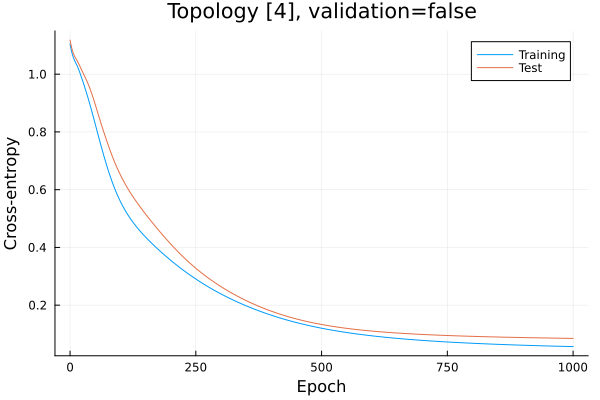

Training accuracy: 98.33333333333333 %
Test accuracy: 96.66666666666667 %
(topology = [4], validation = false, epochs = 1000, returnedEpoch = 1000, stoppedBy = "maxEpochs", trainAccuracy = 0.9833333333333333, validationAccuracy = missing, testAccuracy = 0.9666666666666667, testLossIncreased = false, testLossIncreaseEpochs = Int64[])


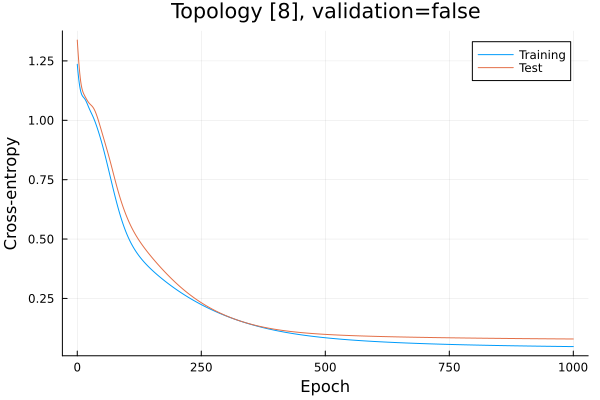

Training accuracy: 98.33333333333333 %
Test accuracy: 96.66666666666667 %
(topology = [8], validation = false, epochs = 1000, returnedEpoch = 1000, stoppedBy = "maxEpochs", trainAccuracy = 0.9833333333333333, validationAccuracy = missing, testAccuracy = 0.9666666666666667, testLossIncreased = false, testLossIncreaseEpochs = Int64[])


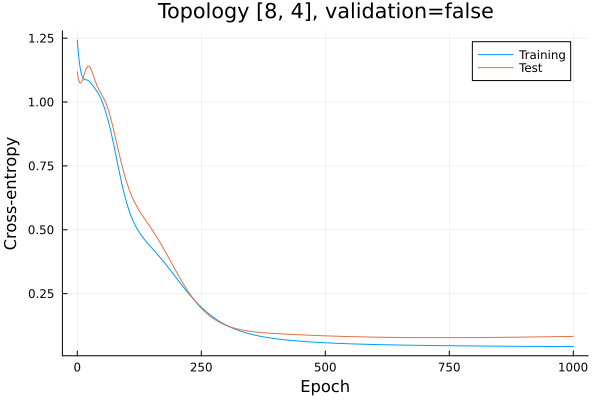

Training accuracy: 98.33333333333333 %
Test accuracy: 96.66666666666667 %
(topology = [8, 4], validation = false, epochs = 1000, returnedEpoch = 1000, stoppedBy = "maxEpochs", trainAccuracy = 0.9833333333333333, validationAccuracy = missing, testAccuracy = 0.9666666666666667, testLossIncreased = true, testLossIncreaseEpochs = [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 731, 732, 733, 734, 735, 736, 737, 738, 739, 740, 741, 742, 743, 744, 745, 746, 747, 748, 749, 750, 751, 752, 753, 754, 755, 756, 757, 758, 759, 760, 761, 762, 763, 764, 765, 766, 767, 768, 769, 770, 771, 772, 773, 774, 775, 776, 777, 778, 779, 780, 781, 782, 783, 784, 785, 786, 787, 788, 789, 790, 791, 792, 793, 794, 795, 796, 797, 798, 799, 800, 801, 802, 803, 804, 805, 806, 807, 808, 809, 810, 811, 812, 813, 814, 815, 816, 817, 818, 819, 820, 821, 822, 823, 824, 825, 826, 827, 828, 829, 830, 831, 832, 833, 834, 835, 836, 837, 838, 839, 840, 841, 842, 843, 844, 845, 846, 847, 848, 849, 850, 851, 852, 

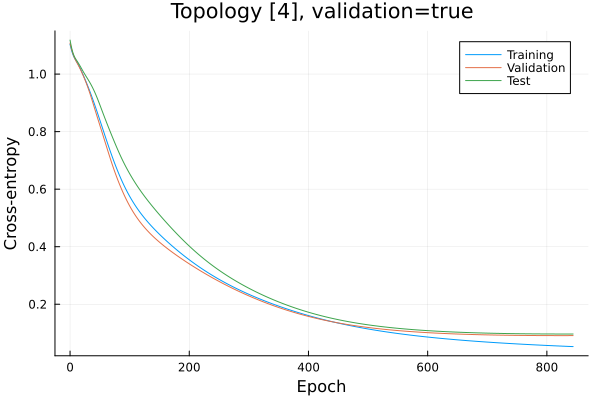

Training accuracy: 98.88888888888889 %
Validation accuracy: 96.66666666666667 %
Test accuracy: 96.66666666666667 %
(topology = [4], validation = true, epochs = 844, returnedEpoch = 824, stoppedBy = "maxEpochsVal", trainAccuracy = 0.9888888888888889, validationAccuracy = 0.9666666666666667, testAccuracy = 0.9666666666666667, testLossIncreased = true, testLossIncreaseEpochs = [833, 834, 835, 836, 837, 838, 839, 840, 841, 842, 843, 844])


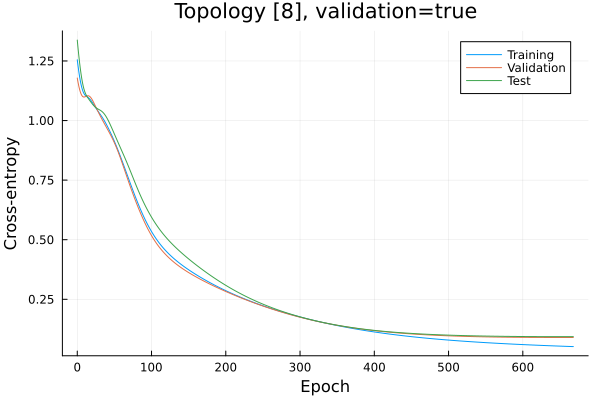

Training accuracy: 98.88888888888889 %
Validation accuracy: 96.66666666666667 %
Test accuracy: 96.66666666666667 %
(topology = [8], validation = true, epochs = 668, returnedEpoch = 648, stoppedBy = "maxEpochsVal", trainAccuracy = 0.9888888888888889, validationAccuracy = 0.9666666666666667, testAccuracy = 0.9666666666666667, testLossIncreased = true, testLossIncreaseEpochs = [653, 654, 655, 656, 657, 658, 659, 660, 661, 662, 663, 664, 665, 666, 667, 668])


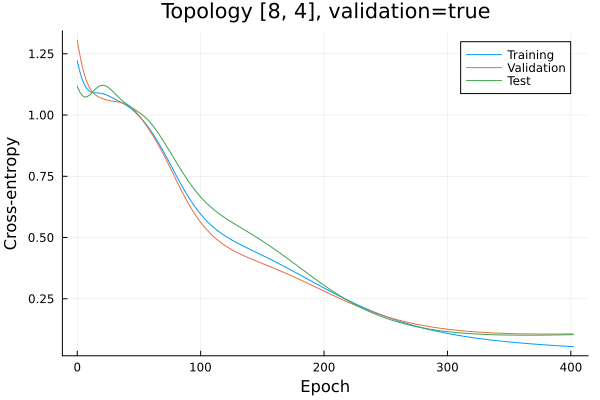

Training accuracy: 98.88888888888889 %
Validation accuracy: 96.66666666666667 %
Test accuracy: 96.66666666666667 %
(topology = [8, 4], validation = true, epochs = 402, returnedEpoch = 382, stoppedBy = "maxEpochsVal", trainAccuracy = 0.9888888888888889, validationAccuracy = 0.9666666666666667, testAccuracy = 0.9666666666666667, testLossIncreased = true, testLossIncreaseEpochs = [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402])


In [37]:
# Load plotting functions for visualizing the loss histories.
using Plots

# Define the parameters, following the structure of Unit 2, Question 2.5.
topologies = ([4], [8], [8,4]);
learningRate = 0.01;
numMaxEpochs = 1000;
minLoss = 0.0;
maxEpochsVal = 20;
Ptest = 0.2;
Pval = 0.2;

# Load the dataset and prepare inputs and targets, as in Unit 2.
# Same test split in both scenarios; normalization parameters use training data only.
# Controls the random train/validation/test split, making it reproducible.
Random.seed!(1)
# Read the Iris CSV: 150 samples, four numeric features, and a species label in column 5.
dataset = readdlm(path, ',');
# Convert the four feature columns to Float32, matching the usual Flux weight type.
# The dot applies the conversion to every element without changing the matrix shape.
# Example: Float32.([5.1 3.5 1.4 0.2]) gives a (1,4) Float32 matrix.
# Float32 uses less memory than Float64 and provides enough precision for this exercise.
inputs = convert(Array{Float32,2}, dataset[:,1:4]);
# Encode species using the same class list for the full dataset.
# Example: setosa -> [true,false,false], versicolor -> [false,true,false].
# The actual column order follows unique(dataset[:,5]) in the Unit 2 helper.
targets = oneHotEncoding(dataset[:,5])
# Reserve 20% for test: with 150 samples, this gives 30 test and 120 remaining samples.
trainval, testidx = holdOut(size(inputs,1), Ptest)
# Reserve 30 validation samples from the remaining 120 using the adjusted fraction 0.25.
# The validation scenario therefore uses 90 training, 30 validation, and 30 test samples.
trainlocal, vallocal = holdOut(length(trainval), Pval / (1-Ptest))
trainidx, validx = trainval[trainlocal], trainval[vallocal]
# Store one named result record per experiment, so fields such as testAccuracy have readable names.
# NamedTuple[] creates an empty vector that will store experiment records with named fields.
# Example record: row = (topology=[8,4], validation=true, epochs=1000, testAccuracy=0.96).
# Access fields by name: row.topology gives [8,4], and row.testAccuracy gives 0.96.
results = NamedTuple[]
# Train different architectures
# [4] and [8] have one hidden layer; [8,4] has two.
for useValidation in (false, true), topology in topologies
    # Choose the appropriate training rows for the current scenario.
    # With validation, idx = trainidx: only training rows are used to fit the network and normalization.
    # Without validation, idx = trainval: all remaining non-test rows are available for training.
    # For Iris, this means 90 training samples with validation or 120 without validation.
    # Example: trainval=[5,2,8,1,6] and trainidx=[5,8,6].
    # useValidation=true selects [5,8,6]; useValidation=false selects [5,2,8,1,6].
    # idx contains original dataset row indices, not the feature values themselves.
    idx = useValidation ? trainidx : trainval
    # Fit the parameters on inputs[idx,:] only, then reuse them for training, validation, and test.
    # Leakage occurs if validation or test values are used to calculate the normalization parameters.
    # Example: training values have min=2 and max=6, while the test set contains a value of 10.
    # With training-only parameters, a training value of 6 becomes (6-2)/(6-2)=1.
    # Including the test value changes max to 10, so that same training value becomes (6-2)/(10-2)=0.5.
    # Test information would therefore change the data used to train the network.
    normalizationParameters = calculateMinMaxNormalizationParameters(inputs[idx,:])
    # Apply the training normalization parameters to each subset and pair inputs with targets.
    # Validation/test values may fall outside [0,1] if they exceed the training range;
    # Keep the normalized inputs in newInputs, as in Unit 2's normalization example.
    # Here, normalize each subset using parameters calculated from training only.
    newInputs = normalizeMinMax(inputs[idx,:], normalizationParameters);

    trainingTargets = targets[idx,:];
    trainingDataset = (newInputs, trainingTargets);

    if useValidation
        validationInputs = normalizeMinMax(inputs[validx,:], normalizationParameters);
        validationTargets = targets[validx,:];
    else
        validationInputs = zeros(Float32,0,size(inputs,2));
        validationTargets = falses(0,size(targets,2));
    end;
    validationDataset = (validationInputs, validationTargets);

    testInputs = normalizeMinMax(inputs[testidx,:], normalizationParameters);
    testTargets = targets[testidx,:];
    testDataset = (testInputs, testTargets);
    # Controls the initial network weights independently of the earlier split.
    Random.seed!(2)
    # Train and unpack the four returned values: model, training loss, validation loss, and test loss.
    (ann, trainingLosses, validationLosses, testLosses) = trainClassANN(topology, trainingDataset;
        validationDataset=validationDataset, testDataset=testDataset,
        maxEpochs=numMaxEpochs, minLoss=minLoss, learningRate=learningRate,
        maxEpochsVal=maxEpochsVal, showText=false);
    # Print test loss at every epoch; index 1 corresponds to epoch 0.
    # println("Test losses: topology=", topology, ", validation=", useValidation)
    # for epoch in 0:length(testLosses)-1
        # println("Epoch ", epoch, ": test loss: ", testLosses[epoch+1])
    # end
    # Plot loss against completed epochs, starting at epoch 0.
    # length(trainingLosses)-1 is the number of updates because the history includes the initial evaluation.
    g = plot(0:length(trainingLosses)-1, trainingLosses; label="Training", xlabel="Epoch", ylabel="Cross-entropy",
             title="Topology $(topology), validation=$(useValidation)")
    # Add a validation curve only when validation was used.
    !isempty(validationLosses) && plot!(g, 0:length(validationLosses)-1, validationLosses; label="Validation")
    plot!(g, 0:length(testLosses)-1, testLosses; label="Test")
    display(g)

    # Save each experiment plot with a unique filename in the Colab files panel.
    filename = "loss_topology_$(join(topology, "_"))_validation_$(useValidation).png"
    savefig(g, joinpath("/content", filename))
    # argmin returns a 1-based position; subtract 1 to obtain the epoch number.
    # Example: validation losses=[0.8,0.5,0.6] -> argmin=2 -> best epoch=1.
    returnedEpoch = useValidation ? argmin(validationLosses)-1 : length(trainingLosses)-1
    # Run the returned network with samples in columns, then transpose predictions back to rows.
    # accuracy compares the predicted class with the target class.
    # Example: 27 correct predictions out of 30 gives 0.9, or 90% accuracy.
    # Follow Unit 2: calculate outputs first, then compare them with the targets.
    outputs = ann(newInputs')';
    trainingAccuracy = accuracy(outputs, trainingTargets);
    validationAccuracy = missing;
    if useValidation
        validationOutputs = ann(validationInputs')';
        validationAccuracy = accuracy(validationOutputs, validationTargets);
    end;
    testOutputs = ann(testInputs')';
    testAccuracy = accuracy(testOutputs, testTargets);
    println("Training accuracy: ", 100*trainingAccuracy, " %");
    if useValidation
        println("Validation accuracy: ", 100*validationAccuracy, " %");
    end;
    println("Test accuracy: ", 100*testAccuracy, " %");
    # Describe which stopping condition was reached. If conditions coincide, this reporting rule
    # prioritizes the epoch limit, then minimum training loss, then validation patience.
    stoppedBy = length(trainingLosses)-1 >= numMaxEpochs ? "maxEpochs" : trainingLosses[end] <= minLoss ? "minLoss" : "maxEpochsVal"
    # Collect architecture, stopping information, returned epoch, and final-model accuracies.
    # These accuracies describe the returned model, while the plotted losses describe the whole run.
    row = (topology=topology, validation=useValidation, epochs=length(trainingLosses)-1,
           returnedEpoch=returnedEpoch, stoppedBy=stoppedBy, trainAccuracy=trainingAccuracy,
           validationAccuracy=validationAccuracy, testAccuracy=testAccuracy,
           # diff(testLosses) computes consecutive changes; any positive change marks at least one increase.
           # Example: [0.8,0.5,0.6] -> differences [-0.3,0.1] -> true.
           # A single increase is not conclusive evidence of overfitting; inspect the overall curve too.
           testLossIncreased=any(diff(testLosses) .> 0),
           testLossIncreaseEpochs=findall(diff(testLosses) .> 0))
    # Append and print the experiment record. Test results describe performance and do not select models.
    push!(results, row)
    println(row)
end

### Question 3.2
> ❓ Has the test error always decreased or has there come a point where it has started to increase?

Test loss did not always decrease. Without validation, [4] and [8] show no increases between consecutive epochs, while [8,4] shows increases at epochs 7–22 and 731–1000. With validation, test loss increases at epochs 833–844 for [4], 653–668 for [8], and 8–21 and 366–402 for [8,4].

### Question 3.3
> ❓ How do the 3 precision values evolve?

Without validation, all three architectures reach 98.33% training accuracy and 96.67% test accuracy; validation accuracy is missing because no validation set is used. With validation, all three reach 98.89% training accuracy, 96.67% validation accuracy, and 96.67% test accuracy. Training accuracy is slightly
higher, and test accuracy is the same in all six runs.


### Question 3.4
> ❓ Which criteria usually stop the training? Why?

Without validation, all three runs stop at 1000 epochs (`maxEpochs`). With validation, [4], [8], and [8,4] stop at epochs 844, 668, and 402, respectively (`maxEpochsVal`), after 20 consecutive epochs without a new best validation loss.


### Question 3.5
> ❓ To which cycle does the ANN returned by the function correspond?

Without validation, all returned networks correspond to epoch 1000. With validation, the returned networks correspond to epochs 824 ([4]), 648 ([8]), and 382 ([8,4]), where validation loss was lowest—20 epochs before training stopped. Test loss does not select the returned network.


# Julia Notes

Julia has a library that allows you to display all kinds of plots in a very simple way.  To load it, simply put `using Plots`, the documentation can be found at http://docs.juliaplots.org/. As always the first should be to install, ifg it is not already installed:

In [8]:
using Pkg; Pkg.add("Plots")

   Resolving package versions...
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`


Actually, `Plots.jl` is not a package for displaying plots, but an interface to a set of libraries for displaying plots.  Plots.jl provides a set of functions that allow, in a unified way, to display plots using one or another library, with the same calls.  That is, what Plots.jl does is to interpret the commands and generate the plots using another graphics library, which it refers to as a backend. Therefore, it is possible to change the graphics library (backend) without having to modify the code, since the calls to the corresponding functions are the same for all backends.

So, first of all, after loading `Plots`, is to select the backend you want to work with.  Julia provides a large number of widely used ones, which you have to install in the usual way if you want to use them. If you don't indicate which one you want to use, Julia defaults to choosing one depending on which ones are installed. To see which backend is being used, you can simply type `backend()`.

In [9]:
using Plots
backend()

Plots.GRBackend()

Some of the most common backends are: Plotly, PyPlot, PlotlyJS and GR. In general, to use a backend, you simply make a call to a function named after the backend itself, but in lowercase. For the 4 given as examples at the beginning of this paragraph, it would be with calls to `plotly()`, `pyplot()`, `plotlyjs()` and `gr()` respectively. As said before, in case it is not installed you will have to install it in the usual way, writing `Pkg.add("Plotly")`, `Pkg.add("PyPlot")`, `Pkg.add("PlotlyJS")` or `Pkg.add("GR")` respectively.   More information about the different backends can be found at https://docs.juliaplots.org/latest/backends/.

In [10]:
# Install the pyplot and plotly if you do not have it

Once the desired backend is loaded, or with the default backend, you can start plotting. The easiest way is to use the plot function, which receives two parameters: the series to be put on the x-axis, and the series to be put on the y-axis, both as vectors, for example:

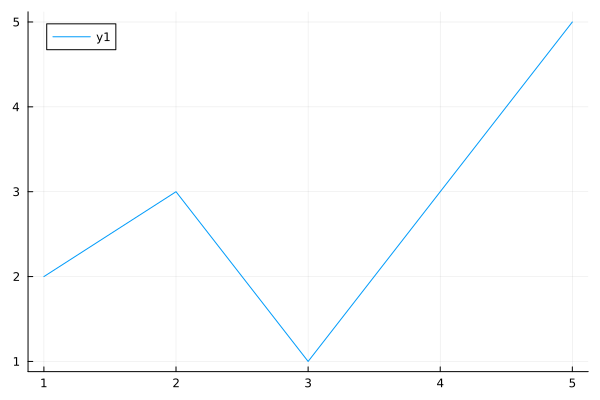

In [11]:
plot(1:5, [2, 3, 1, 3, 5])

In general, if you want to put more than one series on the graph, it is sufficient to specify one column per series in the matrix you pass to it for the y-axis data, for example:

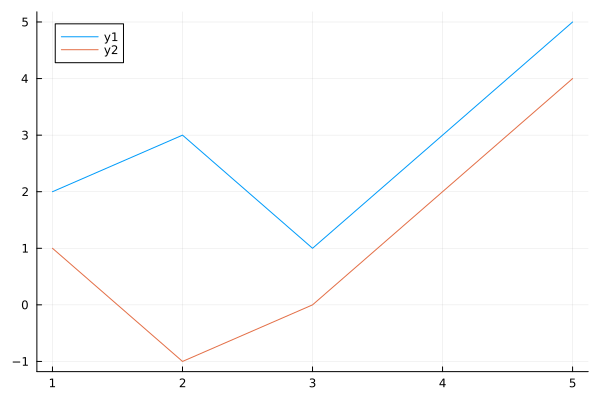

In [12]:
plot(1:5, [2 1; 3 -1; 1 0; 3 2; 5 4])

Another way to do this is to add more series to the plot object that has been created. That is, the call to plot returns an object that can be modified by further calls to `plot!` and passing it as the first parameter (remember that when the name of a function ends in `!` the argument passed is modified). The above example could be done in the following way:

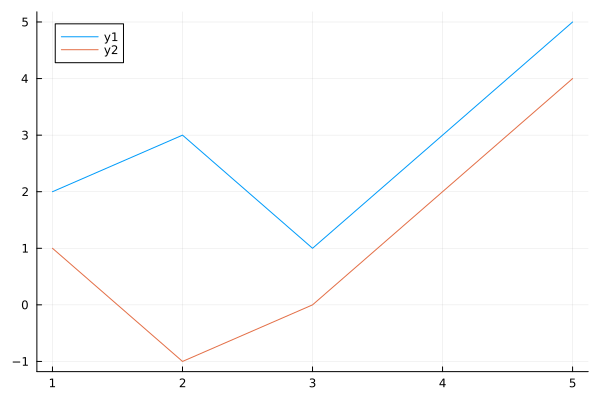

In [13]:
g = plot(1:5, [2, 3, 1, 3, 5])
plot!(g, 1:5, [1, -1, 0, 2, 4])

Or alternatively:

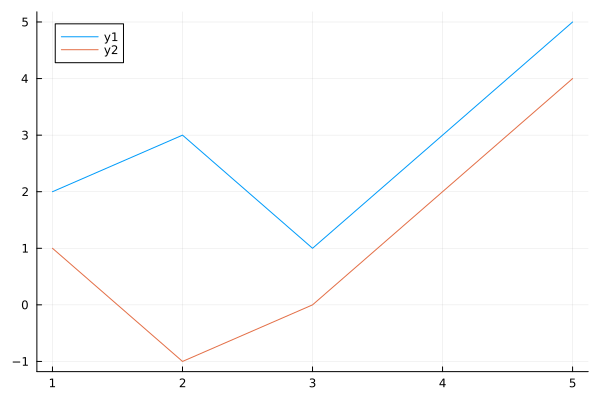

In [14]:
g = plot()
plot!(g, 1:5, [2, 3, 1, 3, 5])
plot!(g, 1:5, [1, -1, 0, 2, 4])

For any of these three possibilities, if this is done in the command interpreter, the graph will appear.  In fact, in the second and third possibilities, more than one graph will appear as you create them. However, if this is done in a script, the graph does not automatically appear.  If we want it to appear, we have to make a call to display in this way:

```julia
    display(g)
```

Besides the function plot, there are many other functions that allow you to represent other types of graphs and charts with the usual names, such as `heatmap`, `plot3d`, `scatter`, `histogram`, `boxplot`, `violin`, etc., all of them with their corresponding function ending in `!`.  As always, you can consult the help of a function by typing, for example:

In [15]:
?boxplot

search: boxplot boxplot! plot pyplot pgfplots pythonplot areaplot



```julia
boxplot(x, y)
boxplot!(x, y)
```

Make a box and whisker plot.

# Keyword arguments

  * `notch`: Bool. Notch the box plot? (false)
  * `whisker_range`: Real. Whiskers extend `whisker_range`*IQR below the first quartile          and above the third quartile. Values outside this range are shown as outliers (1.5)
  * `outliers`: Bool. Show outliers? (true)
  * `whisker_width`: Real or Symbol. Length of whiskers; the options are `:match` to match the box width, `:half`, or a number to indicate the total length. (:half)

# Example

```julia-repl
julia> using StatsPlots
julia> boxplot(repeat([1,2,3],outer=100),randn(300))
```


Generally speaking, it is desired to add more information to the graphs than just the data used in the graph.  This information usually includes title, labels on the axes, legend, markers at each point, line type, colours, etc.  This is usually done through attributes passed as keywords in function calls, such as `axis`, `label`, `line`, `fill`, `marker`, `ticks`, `title`, `xlabel`, `ylabel`, for example:

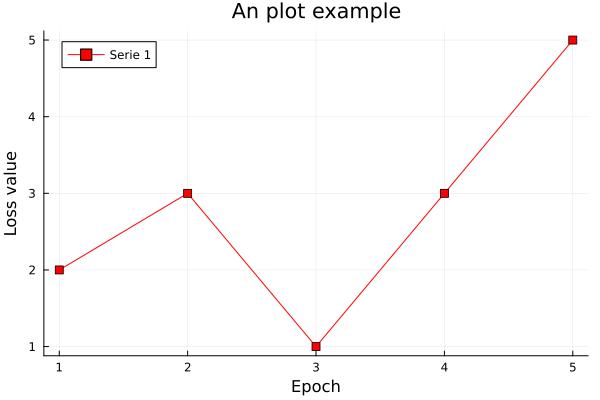

In [16]:
plot(1:5, [2, 3, 1, 3, 5],
    xaxis = "Epoch", yaxis = "Loss value", title = "An plot example",
    marker = :square, color = :red, label = "Serie 1")

A quick overview of the most common keywords can be found at https://docs.juliaplots.org/latest/attributes/.   On the other hand, https://docs.juliaplots.org/latest/generated/supported/tenéis has a complete list of the different types of series, keywords, markers, line styles and scales supported by each backend.  As you can see, the list of graphs and arguments is quite extensive, which gives you an idea of the enormous possibilities Julia offers when it comes to plotting graphs.

Another common issue when displaying graphs is to combine several graphs within a single window.  There are several methods to do this, the simplest and most commonly used being by using the keyword `layout` in the call to the corresponding function to generate the graph containing all of them.  In this sense, it is the easiest way to generate the graphs independently, and combine them later in a new call using the keyword `layout`, which receives as parameter a tuple with the number of rows and columns of the matrix of graphs, for example:

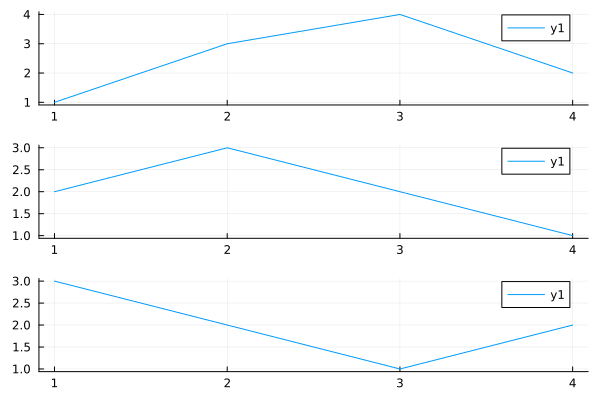

In [17]:
p1 = plot(1:4, [1, 3, 4, 2]);
p2 = plot(1:4, [2, 3, 2, 1]);
p3 = plot(1:4, [3, 2, 1, 2]);
plot(p1, p2, p3, layout = (3,1))

As you could see, the plots asre arrange in a column layout each one in a row, alternatively, if we invert the order the result could be set in a single row as in:

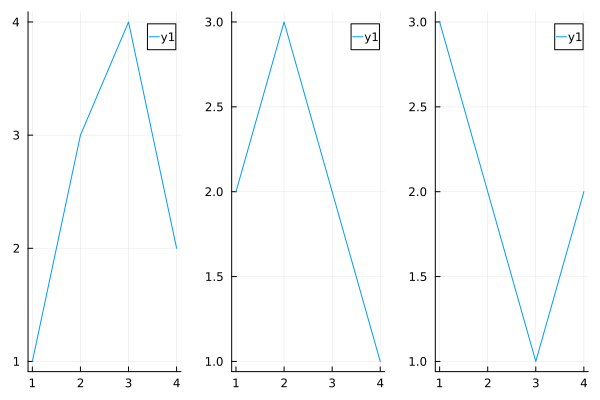

In [18]:
plot(p1, p2, p3, layout = (1,3))

More information on how to combine graphics can be found at https://docs.juliaplots.org/latest/layouts/.

Finally, another very common action is to save the generated graphs.  This can be done by means of the savefig function, which receives as parameters the graph to save and the file name. From the extension indicated in the file name, Julia saves the graph in the indicated format. Some of the most typical formats are `pdf`, `png` or `ps`.  Although this is a very easy way to save the graphs, not all file types are supported by all backends. At https://docs.juliaplots.org/latest/output/ you can check the file formats supported by each backend. For exple with the previous example.

```julia
    g = plot(p1, p2, p3, layout = (1,3))
    savefig(g, 'ExampleSingleRow.png')
```